Accuracy: 0.6948051948051948
              precision    recall  f1-score   support

           0       0.70      0.93      0.80       100
           1       0.67      0.26      0.37        54

    accuracy                           0.69       154
   macro avg       0.68      0.59      0.59       154
weighted avg       0.69      0.69      0.65       154



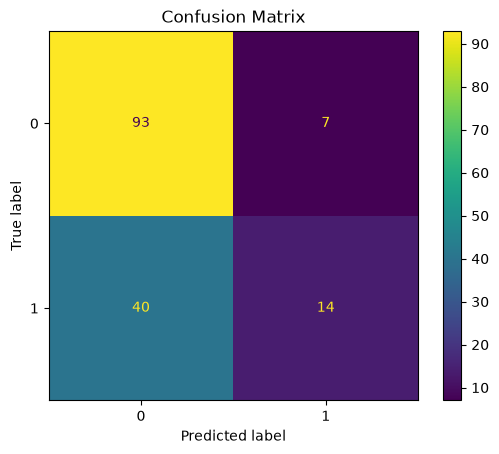

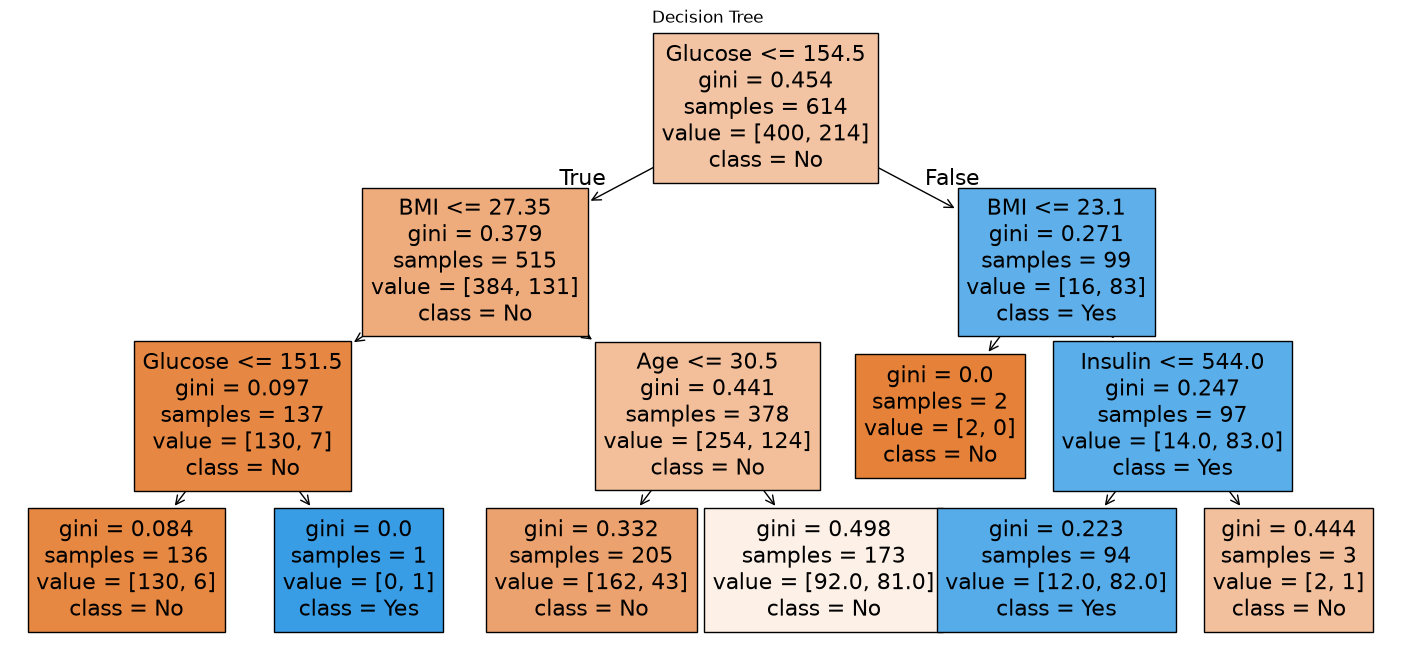

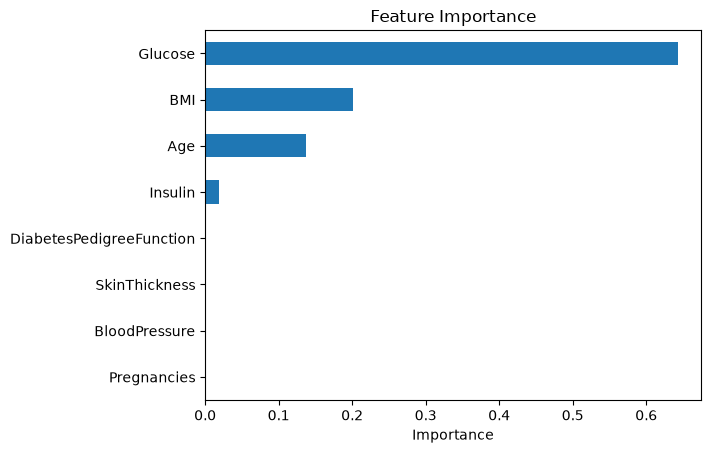

In [1]:
# ===================== REVISION / ONE-SHOT: DECISION TREES =====================
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# 1) Load data (target column of Diabetes.csv is 'Outcome')
df = pd.read_csv("datasets/Diabetes.csv")
X = df.drop("Outcome", axis=1)          # all features except label
y = df["Outcome"]                       # label

# 2) Split 80/20 (stratify keeps class ratio same in both parts)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3) Fit + predict (max_depth limits tree size, avoids overfitting)
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

# 4) Metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot()
plt.title("Confusion Matrix"); plt.show()

# 5) Plot tree
plt.figure(figsize=(18, 8))
plot_tree(model, feature_names=list(X.columns), class_names=["No", "Yes"], filled=True)
plt.title("Decision Tree"); plt.show()

# 6) Feature importance bar plot
pd.Series(model.feature_importances_, index=X.columns).sort_values().plot(kind="barh")
plt.title("Feature Importance"); plt.xlabel("Importance"); plt.show()

# 7) Pruning path: ccp_alpha values -> train one tree per alpha
path = DecisionTreeClassifier(random_state=42).cost_complexity_pruning_path(X_train, y_train)
alphas = path.ccp_alphas[:-1]   # last alpha gives a single-node tree, drop it

# ---------------- VIVA NOTES ----------------
# Split criterion: gini (default) or entropy; tree picks split with max impurity decrease.
# Overfitting control: max_depth, min_samples_leaf, max_leaf_nodes, ccp_alpha (post-pruning).
# feature_importances_ = total impurity decrease from that feature (sums to 1).
# Higher ccp_alpha -> more pruning -> fewer nodes and smaller depth.
# Trees need no scaling; SVM / kNN / LogReg benefit from StandardScaler.
# Read tree plot: each box = split rule, gini, samples, value (class counts), class (majority).

### Q1

Prepare decision tree classifier in python using sklearn library for data set diabetes.csv - (pregnant, glucose, bp, skin, insulin, bmi, pedigree, age, label). Use all features except label as independent variable. Use complete dataset for training and limit the depth of tree upto 3 levels and plot using tree.plotTree() method.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import tree
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

In [3]:
# Load data (real file uses Pima column names; label column is 'Outcome')
df = pd.read_csv("datasets/Diabetes.csv")
print(df.head())
print(df.shape)

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  
(768, 9)


In [4]:
# All features except label -> X, label -> y
X = df.drop("Outcome", axis=1)
y = df["Outcome"]

# Train on complete dataset, depth limited to 3
model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X, y)
print("Training accuracy:", accuracy_score(y, model.predict(X)))

Training accuracy: 0.7760416666666666


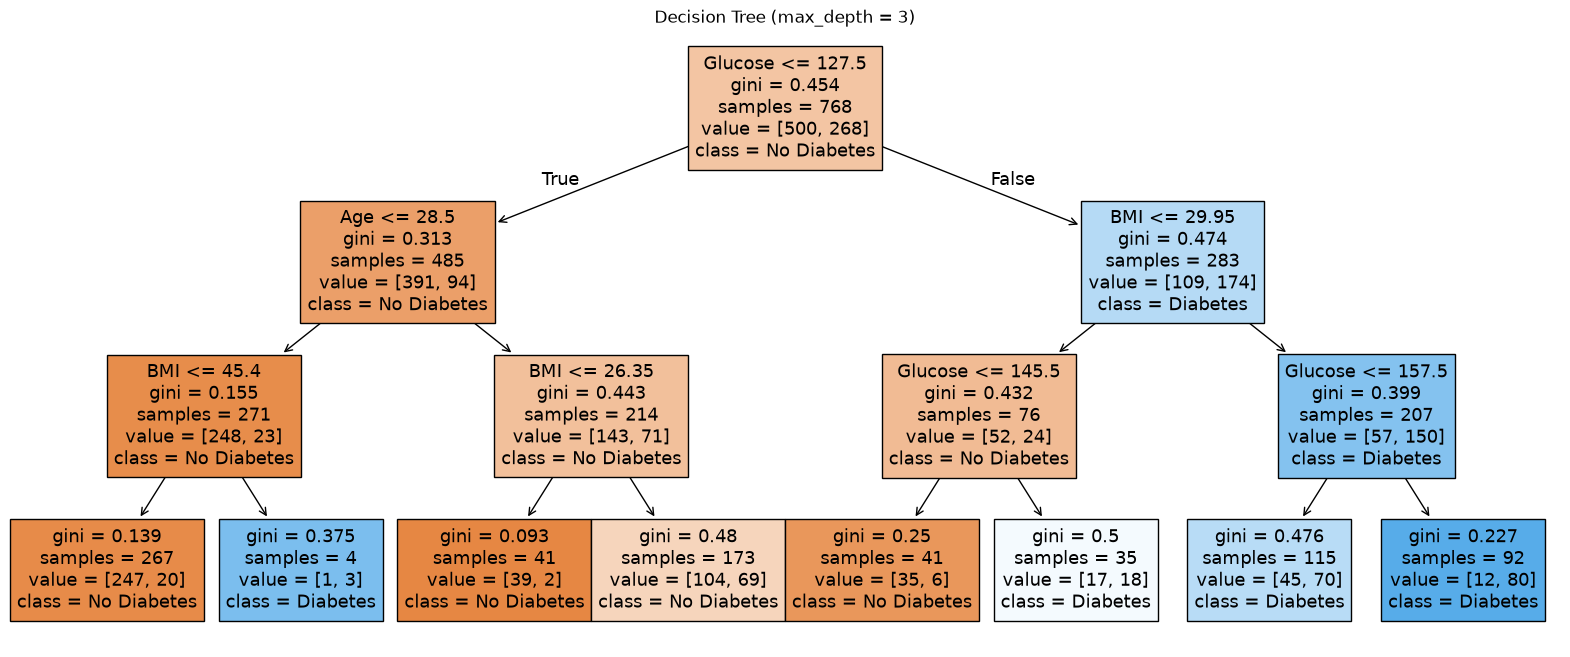

In [5]:
# Question says tree.plotTree(); actual sklearn function is tree.plot_tree()
plt.figure(figsize=(20, 8))
tree.plot_tree(model, feature_names=list(X.columns), class_names=["No Diabetes", "Diabetes"], filled=True)
plt.title("Decision Tree (max_depth = 3)")
plt.show()

### Q2

Using the diabetes dataset, implement a Decision Tree Classifier and determine the importance of each feature in predicting diabetes. Generate different plots to justify your model.

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay, RocCurveDisplay

In [7]:
# Load and split data
df = pd.read_csv("datasets/Diabetes.csv")
X = df.drop("Outcome", axis=1)
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [8]:
# Train decision tree and predict
model = DecisionTreeClassifier(max_depth=4, random_state=42)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.7987012987012987
              precision    recall  f1-score   support

           0       0.82      0.88      0.85       100
           1       0.74      0.65      0.69        54

    accuracy                           0.80       154
   macro avg       0.78      0.76      0.77       154
weighted avg       0.80      0.80      0.80       154



In [9]:
# Feature importance table
imp = pd.Series(model.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp)

Glucose                     0.670911
BMI                         0.174665
Age                         0.138818
Insulin                     0.015606
SkinThickness               0.000000
BloodPressure               0.000000
Pregnancies                 0.000000
DiabetesPedigreeFunction    0.000000
dtype: float64


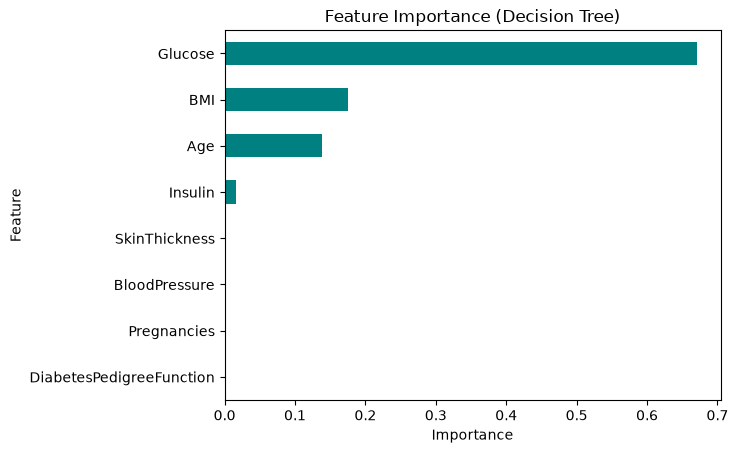

In [10]:
# Plot 1: feature importance bar chart
imp.sort_values().plot(kind="barh", color="teal")
plt.title("Feature Importance (Decision Tree)")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

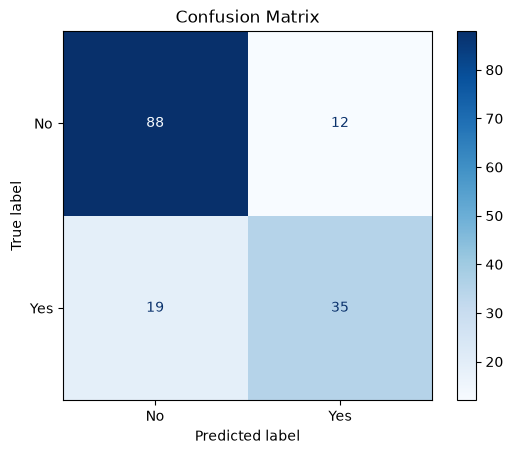

In [11]:
# Plot 2: confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["No", "Yes"], cmap="Blues")
plt.title("Confusion Matrix")
plt.show()

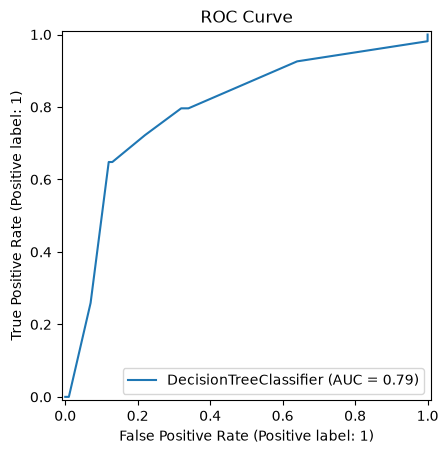

In [12]:
# Plot 3: ROC curve
RocCurveDisplay.from_estimator(model, X_test, y_test)
plt.title("ROC Curve")
plt.show()

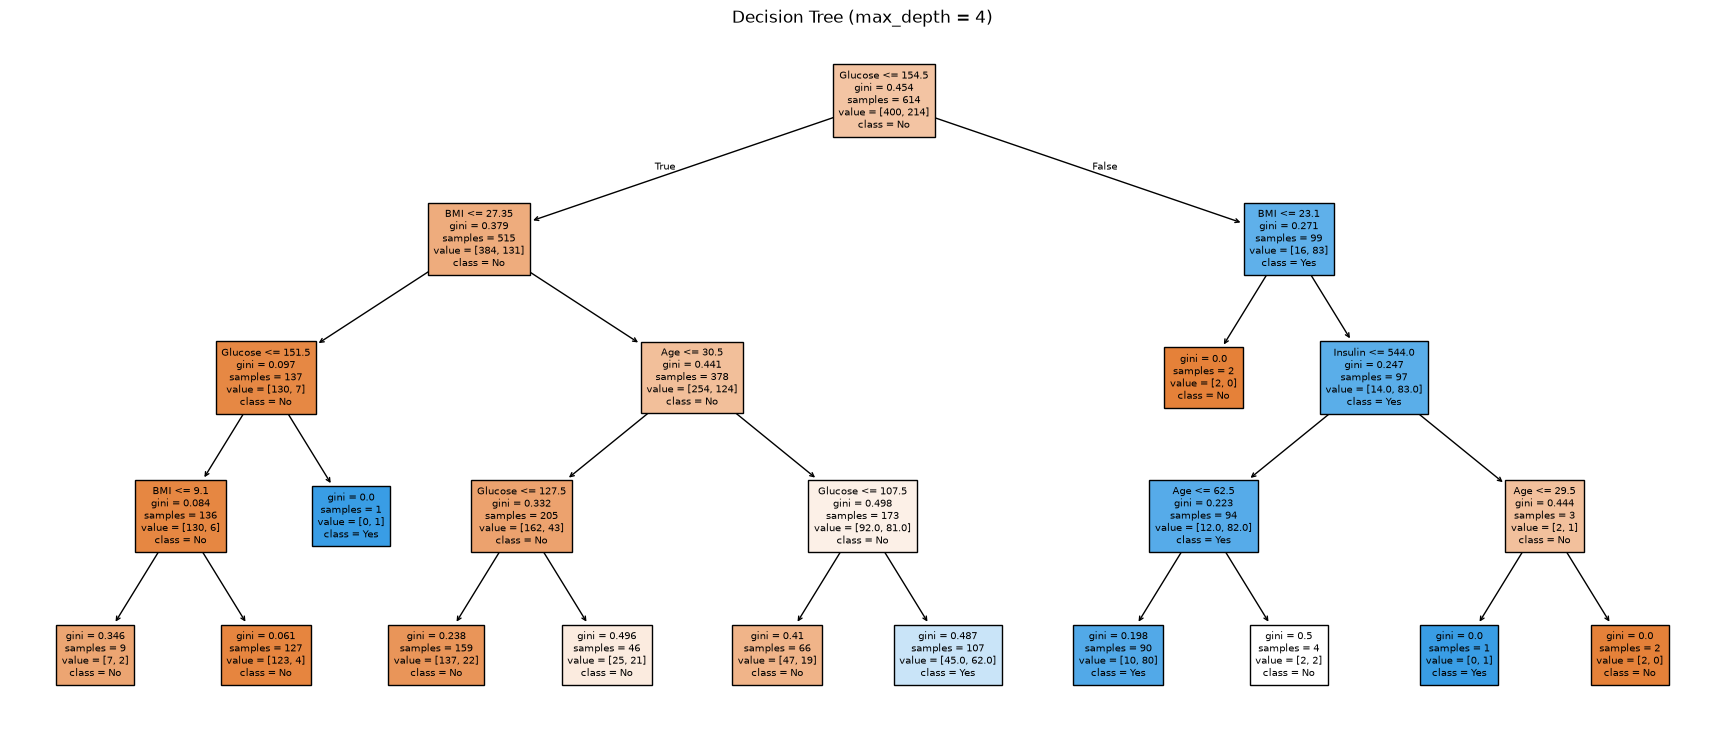

In [13]:
# Plot 4: the tree itself
plt.figure(figsize=(22, 9))
plot_tree(model, feature_names=list(X.columns), class_names=["No", "Yes"], filled=True, fontsize=7)
plt.title("Decision Tree (max_depth = 4)")
plt.show()

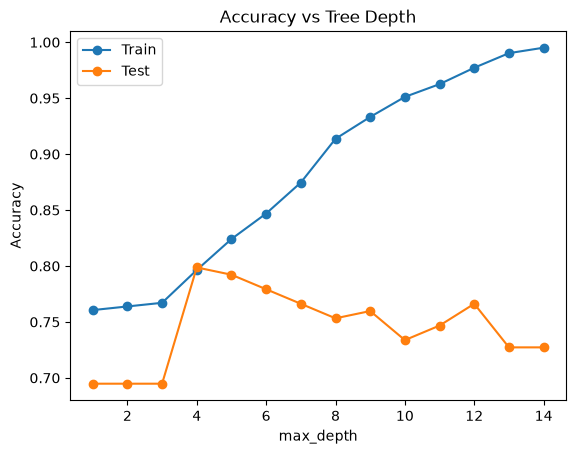

In [14]:
# Plot 5: train vs test accuracy for different depths (justifies chosen depth)
depths = range(1, 15)
train_acc, test_acc = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=42).fit(X_train, y_train)
    train_acc.append(m.score(X_train, y_train))
    test_acc.append(m.score(X_test, y_test))

plt.plot(depths, train_acc, marker="o", label="Train")
plt.plot(depths, test_acc, marker="o", label="Test")
plt.title("Accuracy vs Tree Depth")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

### Q3

Implement a Decision Tree Classifier and compare its performance with a SVM Classifier on the iris dataset. Display the accuracy of both models.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [16]:
# Load iris and split
df = pd.read_csv("datasets/iris.csv")
X = df.drop("variety", axis=1)
y = df["variety"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [17]:
# Decision tree (no scaling needed)
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)
dt_acc = accuracy_score(y_test, dt.predict(X_test))

# SVM needs scaled features
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)
svm = SVC(kernel="rbf", random_state=42)
svm.fit(X_train_s, y_train)
svm_acc = accuracy_score(y_test, svm.predict(X_test_s))

print("Decision Tree accuracy:", dt_acc)
print("SVM accuracy:", svm_acc)

Decision Tree accuracy: 0.9333333333333333
SVM accuracy: 0.9666666666666667


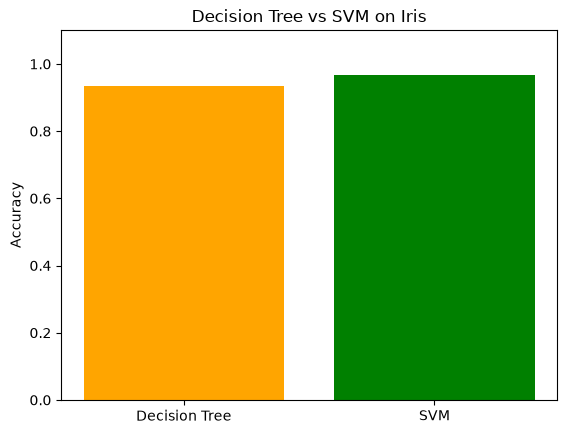

In [18]:
# Bar plot comparing both
plt.bar(["Decision Tree", "SVM"], [dt_acc, svm_acc], color=["orange", "green"])
plt.title("Decision Tree vs SVM on Iris")
plt.ylabel("Accuracy")
plt.ylim(0, 1.1)
plt.show()

### Q4

Build decision tree classifier for iris data set. One with maximum leaf nodes up to 8 and another one with minimum sample per leaf as 5. Compare accuracy of both models.

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

In [20]:
# Load iris and split
df = pd.read_csv("datasets/iris.csv")
X = df.drop("variety", axis=1)
y = df["variety"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

In [21]:
# Model 1: at most 8 leaf nodes
model1 = DecisionTreeClassifier(max_leaf_nodes=8, random_state=42)
model1.fit(X_train, y_train)
acc1 = accuracy_score(y_test, model1.predict(X_test))

# Model 2: every leaf must have at least 5 samples
model2 = DecisionTreeClassifier(min_samples_leaf=5, random_state=42)
model2.fit(X_train, y_train)
acc2 = accuracy_score(y_test, model2.predict(X_test))

print("max_leaf_nodes=8   accuracy:", acc1, "| leaves:", model1.get_n_leaves())
print("min_samples_leaf=5 accuracy:", acc2, "| leaves:", model2.get_n_leaves())

max_leaf_nodes=8   accuracy: 0.9333333333333333 | leaves: 8
min_samples_leaf=5 accuracy: 0.8888888888888888 | leaves: 5


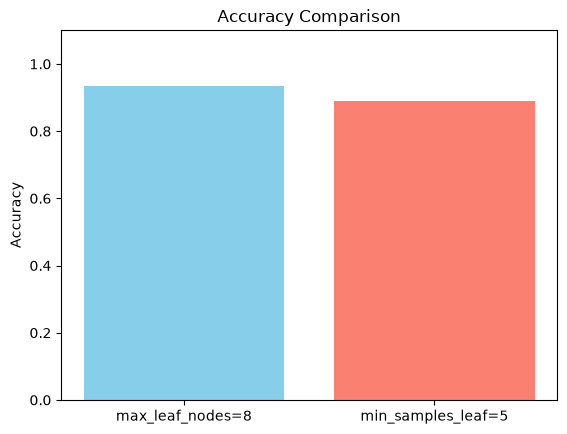

In [22]:
# Compare accuracy
plt.bar(["max_leaf_nodes=8", "min_samples_leaf=5"], [acc1, acc2], color=["skyblue", "salmon"])
plt.title("Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1.1)
plt.show()

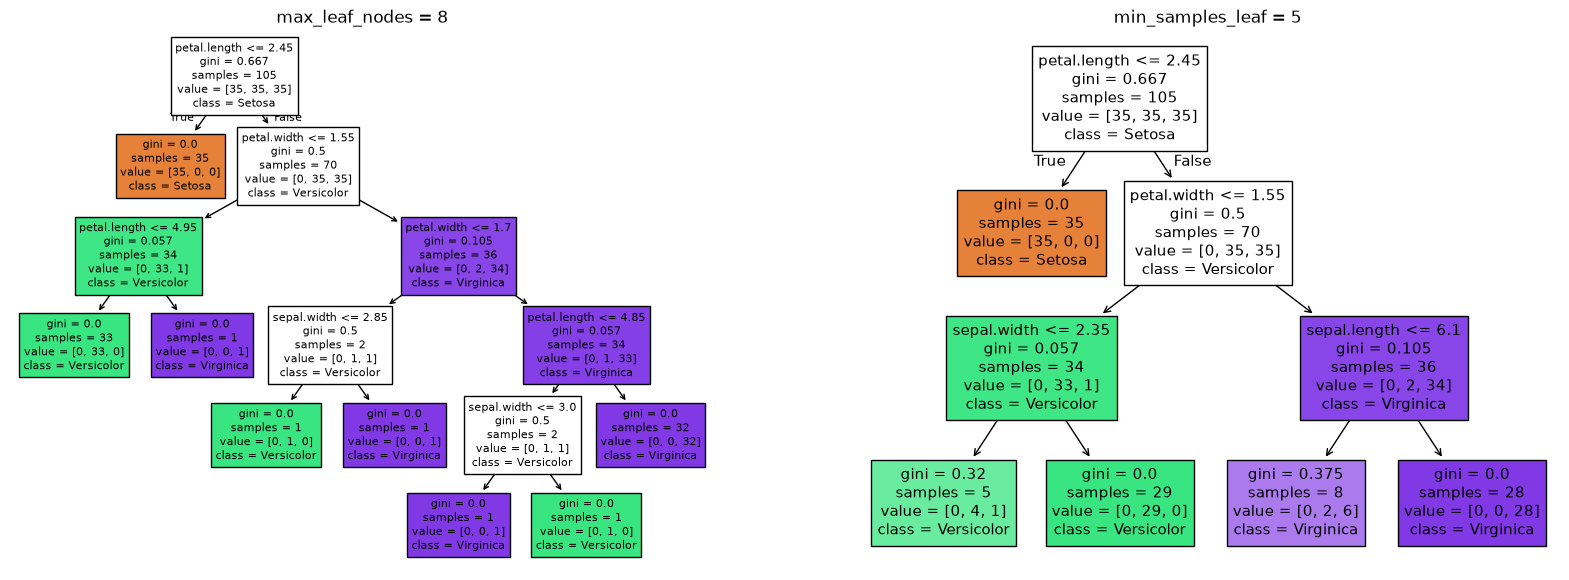

In [23]:
# Show both trees side by side
fig, ax = plt.subplots(1, 2, figsize=(20, 7))
plot_tree(model1, feature_names=list(X.columns), class_names=list(model1.classes_), filled=True, ax=ax[0])
ax[0].set_title("max_leaf_nodes = 8")
plot_tree(model2, feature_names=list(X.columns), class_names=list(model2.classes_), filled=True, ax=ax[1])
ax[1].set_title("min_samples_leaf = 5")
plt.show()

### Q5

Implement a Decision Tree Classifier and compare its performance with a Logistic Classifier on the diabetes dataset. Develop Python code to display the accuracy of both models.

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [25]:
# Load and split
df = pd.read_csv("datasets/Diabetes.csv")
X = df.drop("Outcome", axis=1)
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [26]:
# Decision tree
dt = DecisionTreeClassifier(max_depth=4, random_state=42)
dt.fit(X_train, y_train)
dt_acc = accuracy_score(y_test, dt.predict(X_test))

# Logistic regression (scale features so it converges well)
sc = StandardScaler()
X_train_s = sc.fit_transform(X_train)
X_test_s = sc.transform(X_test)
lr = LogisticRegression(max_iter=1000, random_state=42)
lr.fit(X_train_s, y_train)
lr_acc = accuracy_score(y_test, lr.predict(X_test_s))

print("Decision Tree accuracy:      ", round(dt_acc, 4))
print("Logistic Regression accuracy:", round(lr_acc, 4))

Decision Tree accuracy:       0.7987
Logistic Regression accuracy: 0.7143


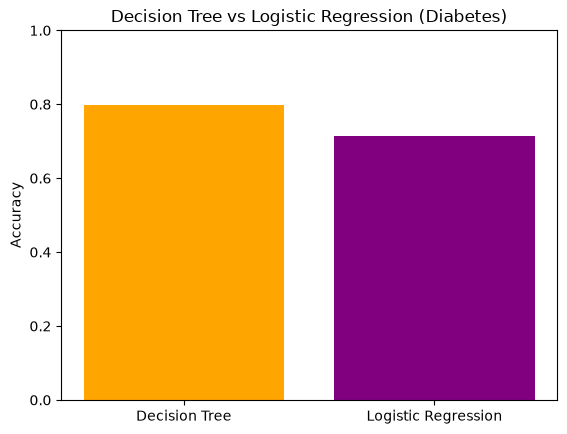

In [27]:
plt.bar(["Decision Tree", "Logistic Regression"], [dt_acc, lr_acc], color=["orange", "purple"])
plt.title("Decision Tree vs Logistic Regression (Diabetes)")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.show()

### Q6

Develop a random dataset using 3 columns and 350 rows. Generate the data frame and apply decision tree classifier to train the model. Compare the accuracy of the model with any 2 other models you can apply on the generated dataset. Generate plot of comparing the accuracy for different models.

In [28]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [29]:
# Random dataset: 350 rows, 3 columns (2 features + 1 target)
X_arr, y_arr = make_classification(n_samples=350, n_features=2, n_informative=2,
                                   n_redundant=0, random_state=42)
df = pd.DataFrame(X_arr, columns=["feature1", "feature2"])
df["target"] = y_arr
print(df.head())
print(df.shape)

   feature1  feature2  target
0 -0.192193  0.458598       1
1 -1.839693  2.689131       1
2 -0.873052  0.849856       1
3  1.488016  0.405660       1
4 -0.817418  2.492329       1
(350, 3)


In [30]:
# Split and scale (scaling helps kNN and logistic regression)
X = df[["feature1", "feature2"]]
y = df["target"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

In [31]:
# Train 3 models and store accuracy
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Logistic Regression": LogisticRegression(random_state=42),
}
scores = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    scores[name] = accuracy_score(y_test, y_pred)
    print(name, "accuracy:", round(scores[name], 4))

Decision Tree accuracy: 1.0
KNN accuracy: 0.9857
Logistic Regression accuracy: 0.9429


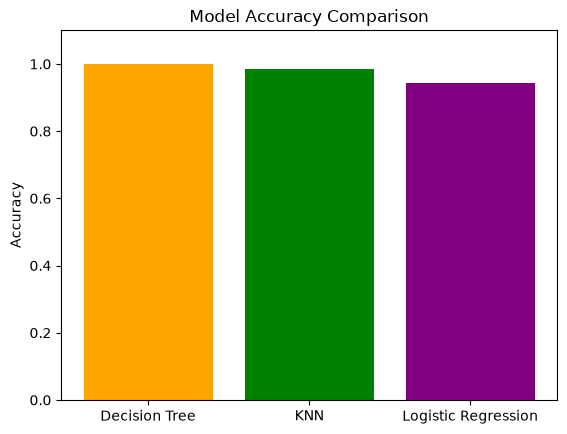

In [32]:
# Compare accuracy
plt.bar(scores.keys(), scores.values(), color=["orange", "green", "purple"])
plt.title("Model Accuracy Comparison")
plt.ylabel("Accuracy")
plt.ylim(0, 1.1)
plt.show()

### Q7

Using the diabetes dataset, implement a Decision Tree Classifier and plot ccp_alpha of built tree against any one DT parameter (node count or maximum depth).

In [33]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [34]:
# Load and split
df = pd.read_csv("datasets/Diabetes.csv")
X = df.drop("Outcome", axis=1)
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [35]:
# Get effective ccp_alpha values from the full tree
model = DecisionTreeClassifier(random_state=42)
path = model.cost_complexity_pruning_path(X_train, y_train)
alphas = path.ccp_alphas[:-1]   # last alpha prunes to a single node, drop it
print("Number of alphas:", len(alphas))

Number of alphas: 58


In [36]:
# Train one tree per alpha, record node count and depth
node_counts, depths, test_acc = [], [], []
for a in alphas:
    m = DecisionTreeClassifier(ccp_alpha=a, random_state=42).fit(X_train, y_train)
    node_counts.append(m.tree_.node_count)
    depths.append(m.tree_.max_depth)
    test_acc.append(m.score(X_test, y_test))

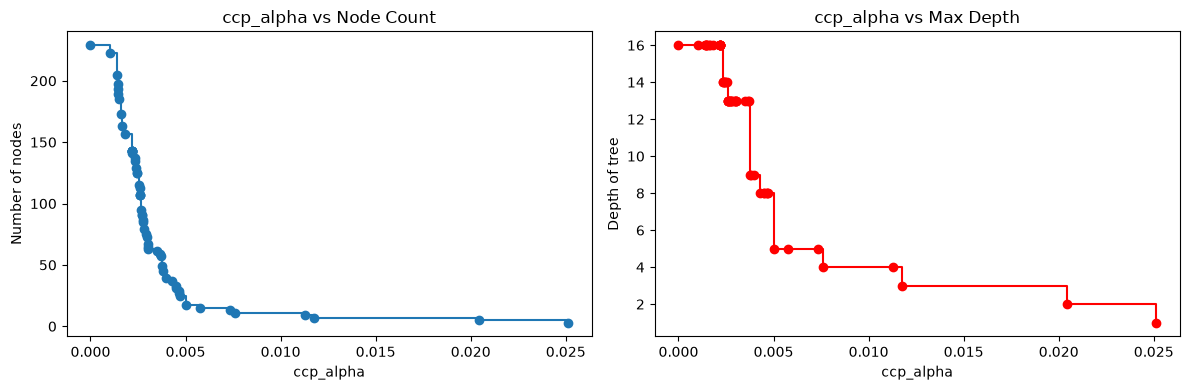

In [37]:
# Plot ccp_alpha vs node count and vs max depth
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(alphas, node_counts, marker="o", drawstyle="steps-post")
ax[0].set_title("ccp_alpha vs Node Count")
ax[0].set_xlabel("ccp_alpha")
ax[0].set_ylabel("Number of nodes")
ax[1].plot(alphas, depths, marker="o", color="red", drawstyle="steps-post")
ax[1].set_title("ccp_alpha vs Max Depth")
ax[1].set_xlabel("ccp_alpha")
ax[1].set_ylabel("Depth of tree")
plt.tight_layout()
plt.show()

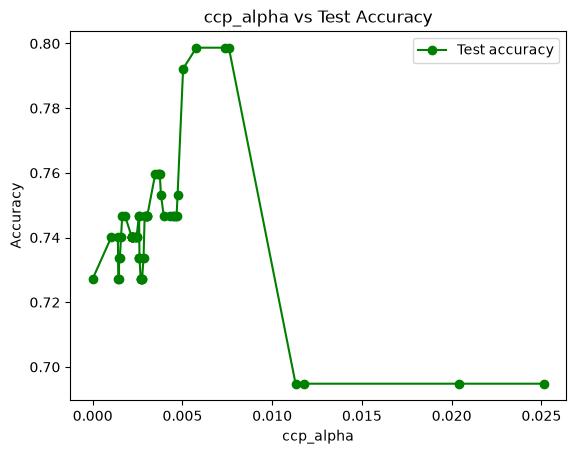

Best ccp_alpha: 0.005776412331786926 | accuracy: 0.7987012987012987


In [38]:
# Extra: test accuracy vs ccp_alpha (helps pick best alpha)
plt.plot(alphas, test_acc, marker="o", color="green", label="Test accuracy")
plt.title("ccp_alpha vs Test Accuracy")
plt.xlabel("ccp_alpha")
plt.ylabel("Accuracy")
plt.legend()
plt.show()
best = alphas[test_acc.index(max(test_acc))]
print("Best ccp_alpha:", best, "| accuracy:", max(test_acc))